# Шаг 1: Исследование структуры файлов

In [1]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import pickle
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 100)

print(" Библиотеки импортированы")
print(f"Pandas: {pd.__version__}")

 Библиотеки импортированы
Pandas: 2.3.3


In [2]:
data_dir = '../data/raw'


for file in sorted(os.listdir(data_dir)):
    file_path = os.path.join(data_dir, file)
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    size_gb = size_mb / 1024
    print(f" {file:<25} | {size_mb:>8.2f} MB ({size_gb:.2f} GB)")

 query_clicks.parquet      |   620.74 MB (0.61 GB)
 sku_desc.parquet          |   335.84 MB (0.33 GB)
 skus.pkl                  |  1492.64 MB (1.46 GB)


# Шаг 2: Исследуем каждый файл по отдельности

## SKU DESCRIPTIONS

In [3]:

table = pq.read_table('../data/raw/sku_desc.parquet')
df_desc = table.slice(0, 5000).to_pandas()  

print(f" Shape: {df_desc.shape}")
print(f" Columns: {df_desc.columns.tolist()}")
print(f" Memory: {df_desc.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print()

display(df_desc.head())


 Shape: (5000, 3)
 Columns: ['sku_id', 'title', 'description']
 Memory: 8.51 MB



,sku_id,title,description
0,401054646,Зеркало SSG MIRRORS Light XL,Зеркало с подсветкой в алюминиевой раме SSG MIRRORS — отличное решение для вашего интерьера. Оно...
1,401796168,Набор отверток GSS -,Отвертка с двусторонней рукояткой и ударной функцией.\n\nХарактеристики:\n• Тип головки: плоская...
2,401951584,Детские столовые приборы GSS -,Чашка-поильник с наносеребряным покрытием для детей от 6 месяцев.\n\nХарактеристики:\n• Серия: N...
3,401380245,Брелок UNIMALL -,Набор для творчества с брелоком-рыбкой.\n\nХарактеристики:\n• Цвет: розовый\n• Декоративные элем...
4,20104914,"Уцененный конвектор Coolfort CF-3942, отличный",Внешний вид: «Отличный».<br>Новый товар. Витринный/демонстрационный образец.<br>Товар может имет...


ТИПЫ ДАННЫХ И ПРОПУСКИ (sku_desc)


,dtype,non_null,null_count,null_pct
sku_id,int64,5000,0,0.0
title,object,5000,0,0.0
description,object,5000,0,0.0


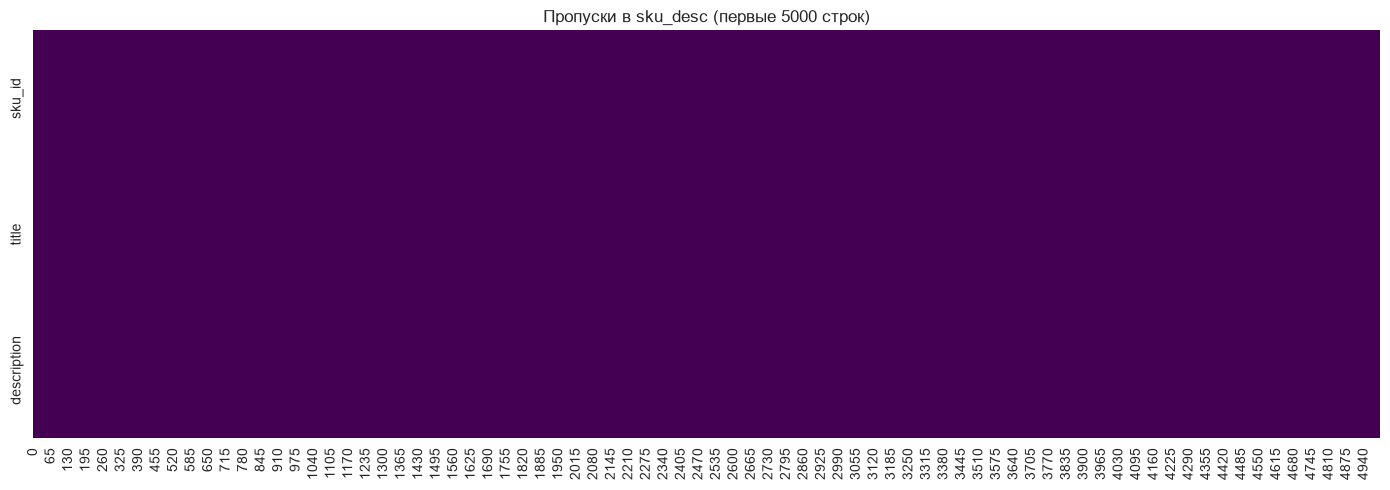

In [4]:

print("ТИПЫ ДАННЫХ И ПРОПУСКИ (sku_desc)")

info_df = pd.DataFrame({
    'dtype': df_desc.dtypes,
    'non_null': df_desc.count(),
    'null_count': df_desc.isnull().sum(),
    'null_pct': (df_desc.isnull().sum() / len(df_desc) * 100).round(2)
})
display(info_df)


plt.figure(figsize=(14, 5))
sns.heatmap(df_desc.isnull().T, cmap='viridis', cbar=False, yticklabels=True)
plt.title('Пропуски в sku_desc (первые 5000 строк)')
plt.tight_layout()
plt.show()

In [5]:
print("АНАЛИЗ ТЕКСТОВЫХ ПОЛЕЙ")

text_cols = df_desc.select_dtypes(include=['object']).columns.tolist()
print(f"Текстовые колонки: {text_cols}")
print()

for col in text_cols:
    print(f" Колонка: {col}")
    print(f"   Уникальных значений: {df_desc[col].nunique()}")
    print(f"   Средняя длина: {df_desc[col].astype(str).str.len().mean():.0f} символов")
    print(f"   Максимальная длина: {df_desc[col].astype(str).str.len().max():.0f}")
    print()
    
    sample = df_desc[col].dropna().iloc[0] if not df_desc[col].dropna().empty else "NaN"
    print(f"   Пример:")
    print(f"   {'─' * 50}")
    print(f"   {str(sample)[:800]}")
    print(f"   {'─' * 50}")
    print()

АНАЛИЗ ТЕКСТОВЫХ ПОЛЕЙ
Текстовые колонки: ['title', 'description']

 Колонка: title
   Уникальных значений: 3609
   Средняя длина: 41 символов
   Максимальная длина: 186

   Пример:
   ──────────────────────────────────────────────────
   Зеркало SSG MIRRORS Light XL
   ──────────────────────────────────────────────────

 Колонка: description
   Уникальных значений: 4453
   Средняя длина: 780 символов
   Максимальная длина: 18723

   Пример:
   ──────────────────────────────────────────────────
   Зеркало с подсветкой в алюминиевой раме SSG MIRRORS — отличное решение для вашего интерьера. Оно испускает холодный белый свет (6000К) или теплый свет (3000К), добавляя элегантности в любое пространство. Светодиодная подсветка обрамляет зеркало, создавая эффект легкости и парения.<br><br>Данное зеркало идеально подходит как для прихожей, так и для спальни или ванной комнаты и может быть установлено как вертикально, так и горизонтально благодаря отверстиям в раме.<br><br>Алюминиевая рама зерка

РАСПРЕДЕЛЕНИЕ ДЛИН ТЕКСТОВ


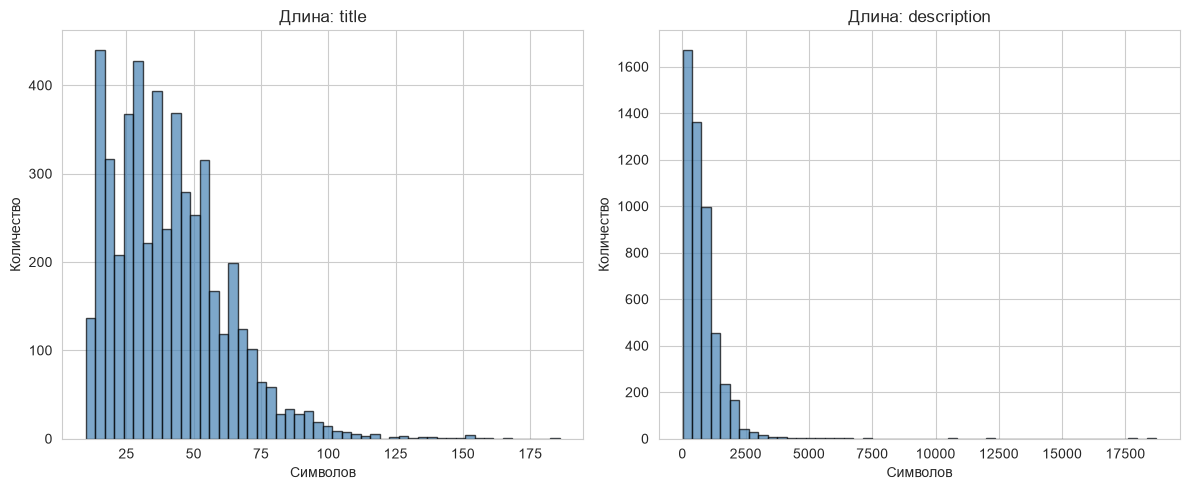

In [6]:
print("РАСПРЕДЕЛЕНИЕ ДЛИН ТЕКСТОВ")

fig, axes = plt.subplots(1, len(text_cols), figsize=(6 * len(text_cols), 5))
if len(text_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, text_cols):
    lengths = df_desc[col].astype(str).str.len()
    ax.hist(lengths, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(f'Длина: {col}')
    ax.set_xlabel('Символов')
    ax.set_ylabel('Количество')

plt.tight_layout()
plt.show()

In [7]:
print("АНАЛИЗ TITLE — поиск паттернов")


print("\n 10 случайных title:")
for idx, title in df_desc['title'].sample(10, random_state=42).items():
    print(f"  [{idx}] {title}")

# Ищем паттерны: бренды в начале, цифры, специальные символы
print("\n Паттерны в title:")
print(f"  Начинаются с цифры: {(df_desc['title'].str[0].str.isdigit()).sum()}")
print(f"  Содержат '-': {df_desc['title'].str.contains('-', na=False).sum()}")
print(f"  Содержат цифры: {df_desc['title'].str.contains(r'\d', na=False).sum()}")

АНАЛИЗ TITLE — поиск паттернов

 10 случайных title:
  [1501] Подушка декоративная PrintyFull Цветочный узор: розы FP412048650
  [2586] Намордник для животных GSS -
  [2653] Наушники True Wireless Haylou MoriPods White
  [1055] Рюкзак GSS -
  [705] Моноблок Sony VAIO VPC-L12M1R Black
  [106] Коврик для мыши PANiN Коврик для мыши 22x18 EIDGSP40685
  [589] Ручной отпариватель Vixter GSH-1790
  [2468] Унитаз Enio Tecnico
  [2413] Электрочайник GSS -
  [1600] Микроволновая печь соло Hisense H20MOBSD1H

 Паттерны в title:
  Начинаются с цифры: 5
  Содержат '-': 2557
  Содержат цифры: 3021


In [8]:
print("АНАЛИЗ DESCRIPTION — структура")


# Сколько описаний содержат "Характеристики:"
has_chars = df_desc['description'].str.contains('Характеристики', na=False).sum()
print(f" Содержат 'Характеристики:': {has_chars} из {len(df_desc)} ({has_chars/len(df_desc)*100:.1f}%)")

# Сколько содержат HTML-теги
has_html = df_desc['description'].str.contains(r'<br\s*/?>|<p>|<div>', na=False, regex=True).sum()
print(f" Содержат HTML-теги: {has_html} ({has_html/len(df_desc)*100:.1f}%)")

# Ищем паттерн "Ключ: значение"
import re
pattern = r'•\s*([^:]{2,30}):\s*([^\n•]{1,100})'
sample = df_desc['description'].iloc[1]  # второй товар из примера
matches = re.findall(pattern, sample)
print(f"\n Пример парсинга 'Ключ: значение' из description:")
for key, value in matches[:5]:
    print(f"   {key.strip()} → {value.strip()}")

АНАЛИЗ DESCRIPTION — структура
 Содержат 'Характеристики:': 1622 из 5000 (32.4%)
 Содержат HTML-теги: 2420 (48.4%)

 Пример парсинга 'Ключ: значение' из description:
   Тип головки → плоская, крестовая
   Наличие магнита → да
   Материал → хромомолибденовая сталь
   Тип → ударная
   Конструкция → сквозной стержень


In [9]:
print("ПОИСК АТРИБУТОВ В ДАННЫХ")


# Ищем упоминания типичных атрибутов электроники
attributes_to_find = {
    'Цвет': r'[Цц]вет[:\s]+([а-яА-ЯёЁa-zA-Z]+)',
    'Память/GB': r'(\d+)\s*[Гг][Бб]',
    'Диагональ': r'(\d+[\.,]\d+)\s*["\'дюйм]',
    'Бренд': r'(Samsung|Apple|Xiaomi|LG|Sony|Bosch|Philips)',
    'Мощность': r'(\d+)\s*[Вв]т',
    'Вес': r'(\d+[\.,]?\d*)\s*[кгКГ]',
}

for attr_name, pattern in attributes_to_find.items():
    count = df_desc['description'].str.contains(pattern, na=False, regex=True).sum()
    title_count = df_desc['title'].str.contains(pattern, na=False, regex=True).sum()
    print(f"  {attr_name}: description={count}, title={title_count}")

ПОИСК АТРИБУТОВ В ДАННЫХ
  Цвет: description=1219, title=4
  Память/GB: description=207, title=7
  Диагональ: description=437, title=33
  Бренд: description=232, title=279
  Мощность: description=448, title=11
  Вес: description=1576, title=74
